In [1]:
import pandas as pd


In [2]:
df = pd.read_csv("regression_2_1.csv")

In [3]:
df.head()

,match_id,elo_difference,win_rate_difference,draw_rate_difference,rest_difference,home_advantage,world_cup_experience_difference,head_to_head_balance,competitive_share_difference,goal_difference
0,M001,2.201330,0.1,0.1,2,1,1.808289,0.166667,-0.5,2
1,M002,0.686736,0.1,-0.3,1,0,2.277267,0.000000,-0.6,1
2,M003,1.677483,0.1,-0.1,1,1,0.559616,0.000000,-0.7,0
3,M004,-0.478004,0.1,-0.1,-1,1,0.305382,0.142857,-0.4,3
4,M006,-0.275339,-0.3,0.0,0,0,0.646627,-0.500000,-0.4,2


In [4]:
df.shape

(104, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   match_id                         104 non-null    object 
 1   elo_difference                   104 non-null    float64
 2   win_rate_difference              104 non-null    float64
 3   draw_rate_difference             104 non-null    float64
 4   rest_difference                  104 non-null    int64  
 5   home_advantage                   104 non-null    int64  
 6   world_cup_experience_difference  104 non-null    float64
 7   head_to_head_balance             104 non-null    float64
 8   competitive_share_difference     104 non-null    float64
 9   goal_difference                  104 non-null    int64  
dtypes: float64(6), int64(3), object(1)
memory usage: 8.3+ KB


In [6]:
df.isnull().sum()

match_id                           0
elo_difference                     0
win_rate_difference                0
draw_rate_difference               0
rest_difference                    0
home_advantage                     0
world_cup_experience_difference    0
head_to_head_balance               0
competitive_share_difference       0
goal_difference                    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,elo_difference,win_rate_difference,draw_rate_difference,rest_difference,home_advantage,world_cup_experience_difference,head_to_head_balance,competitive_share_difference,goal_difference
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,0.409050,0.045192,-0.024038,0.086538,0.067308,0.407296,0.009295,-0.055769,0.480769
std,1.693893,0.276553,0.227052,1.520798,0.348768,1.576663,0.294153,0.248813,2.024034
min,-3.838195,-0.700000,-0.600000,-8.000000,-1.000000,-3.412247,-0.714286,-0.700000,-4.000000
25%,-0.951197,-0.100000,-0.125000,0.000000,0.000000,-0.665871,-0.148810,-0.200000,-1.000000
50%,0.337435,0.100000,0.000000,0.000000,0.000000,0.454129,0.000000,0.000000,0.000000
75%,1.837845,0.200000,0.125000,1.000000,0.000000,1.419126,0.212500,0.100000,2.000000
max,4.027091,0.800000,0.600000,5.000000,1.000000,4.727388,0.714286,0.600000,6.000000


In [9]:
numeric_df = df.drop(columns=["match_id"])
numeric_df.corr()

,elo_difference,win_rate_difference,draw_rate_difference,rest_difference,home_advantage,world_cup_experience_difference,head_to_head_balance,competitive_share_difference,goal_difference
elo_difference,1.000000,0.737147,-0.163905,0.039535,0.036627,0.789022,0.368874,-0.409152,0.610961
win_rate_difference,0.737147,1.000000,-0.546887,0.002153,0.139276,0.643712,0.258059,-0.130920,0.479414
draw_rate_difference,-0.163905,-0.546887,1.000000,0.056693,-0.126493,-0.342924,-0.038917,0.106650,-0.021086
rest_difference,0.039535,0.002153,0.056693,1.000000,0.080434,0.104088,-0.056434,-0.053832,0.093591
home_advantage,0.036627,0.139276,-0.126493,0.080434,1.000000,0.102437,0.027190,-0.482159,0.160015
world_cup_experience_difference,0.789022,0.643712,-0.342924,0.104088,0.102437,1.000000,0.209402,-0.342832,0.570259
head_to_head_balance,0.368874,0.258059,-0.038917,-0.056434,0.027190,0.209402,1.000000,-0.014673,0.407820
competitive_share_difference,-0.409152,-0.130920,0.106650,-0.053832,-0.482159,-0.342832,-0.014673,1.000000,-0.243130
goal_difference,0.610961,0.479414,-0.021086,0.093591,0.160015,0.570259,0.407820,-0.243130,1.000000


In [10]:
numeric_df.corr()["goal_difference"].sort_values(ascending=False)

goal_difference                    1.000000
elo_difference                     0.610961
world_cup_experience_difference    0.570259
win_rate_difference                0.479414
head_to_head_balance               0.407820
home_advantage                     0.160015
rest_difference                    0.093591
draw_rate_difference              -0.021086
competitive_share_difference      -0.243130
Name: goal_difference, dtype: float64

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [12]:
X = df.drop(columns=["match_id", "goal_difference"])
y = df["goal_difference"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
y_pred = model.predict(X_test)

In [16]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.5262627465946341
RMSE: 1.8361225238386192
R²: 0.1830969495365672


In [17]:
coefficients = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_
})

coefficients.sort_values(by="Coefficient", ascending=False)

,Variable,Coefficient
2,draw_rate_difference,2.563810
1,win_rate_difference,2.059820
6,head_to_head_balance,1.712741
4,home_advantage,1.567900
5,world_cup_experience_difference,0.354041
7,competitive_share_difference,0.340410
0,elo_difference,0.150485
3,rest_difference,0.041223


In [18]:
print("Intercept:", model.intercept_)

Intercept: 0.15414693885452124


In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X.copy()

vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.sort_values("VIF", ascending=False)

,Variable,VIF
0,elo_difference,8.892473
1,win_rate_difference,5.638526
5,world_cup_experience_difference,3.493854
7,competitive_share_difference,2.594309
2,draw_rate_difference,2.338386
4,home_advantage,1.774903
6,head_to_head_balance,1.272147
3,rest_difference,1.042077


In [20]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_with_const = add_constant(X)

vif2 = pd.DataFrame()
vif2["Variable"] = X_with_const.columns
vif2["VIF"] = [
    variance_inflation_factor(X_with_const.values, i)
    for i in range(X_with_const.shape[1])
]

vif2

,Variable,VIF
0,const,1.114649
1,elo_difference,8.495407
2,win_rate_difference,5.530537
3,draw_rate_difference,2.324496
4,rest_difference,1.039165
5,home_advantage,1.745512
6,world_cup_experience_difference,3.281154
7,head_to_head_balance,1.274445
8,competitive_share_difference,2.469495


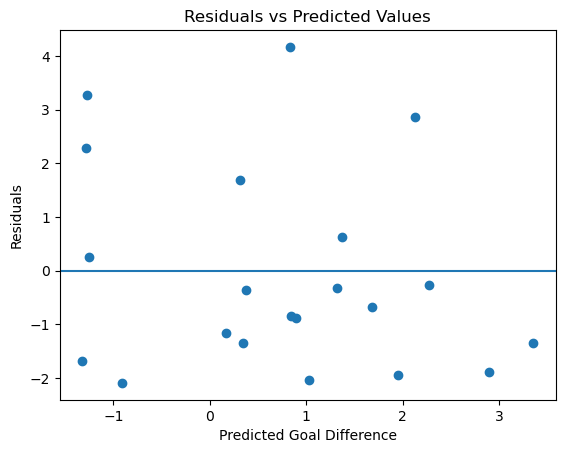

In [21]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Goal Difference")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

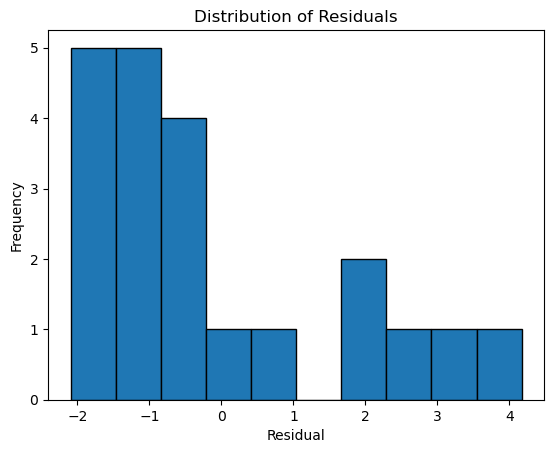

In [22]:
plt.hist(residuals, bins=10, edgecolor="black")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

In [23]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Error": y_test - y_pred
})

results

,Actual,Predicted,Error
30,-1,0.344400,-1.344400
65,-1,-1.256599,0.256599
64,5,0.831208,4.168792
53,1,-1.278832,2.278832
45,0,1.946776,-1.946776
93,-3,-0.905548,-2.094452
91,-1,1.031414,-2.031414
47,5,2.132426,2.867574
10,0,0.891456,-0.891456
0,2,3.353584,-1.353584


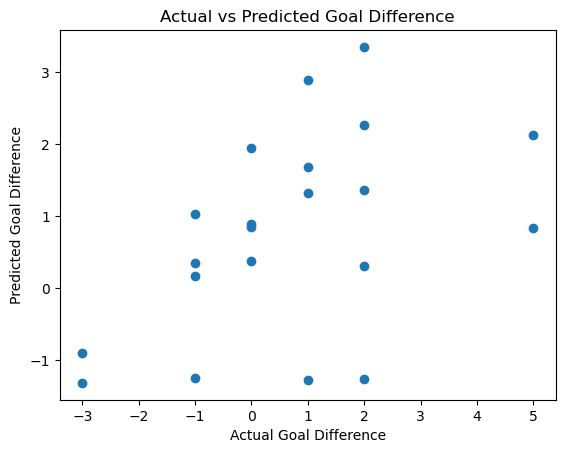

In [24]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Goal Difference")
plt.ylabel("Predicted Goal Difference")
plt.title("Actual vs Predicted Goal Difference")
plt.show()

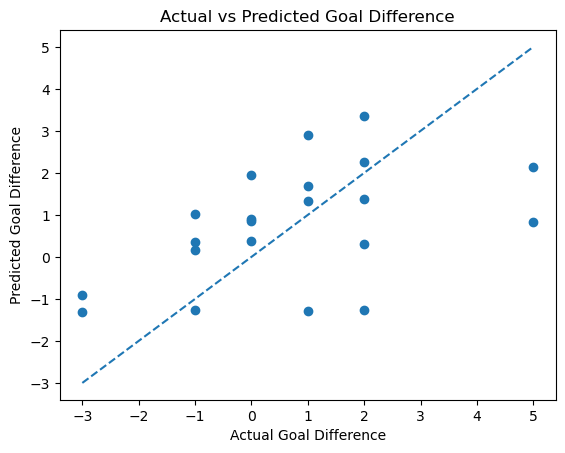

In [25]:
plt.scatter(y_test, y_pred)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual Goal Difference")
plt.ylabel("Predicted Goal Difference")
plt.title("Actual vs Predicted Goal Difference")
plt.show()

In [26]:
import statsmodels.api as sm

X_ols = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_ols).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.546
Model:                            OLS   Adj. R-squared:                  0.497
Method:                 Least Squares   F-statistic:                     11.12
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           3.53e-10
Time:                        18:46:25   Log-Likelihood:                -142.83
No. Observations:                  83   AIC:                             303.7
Df Residuals:                      74   BIC:                             325.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     